<h2 style= "background-color: #222; 
            padding: 20px; 
            font: bold 26px tahoma;
            text-align:center; 
            color:gold;
            border: 2px solid tomato;
            border-radius: 5px;">   
    😍🥰The Link To My Streamlit Web APP For This Project In The Last Section Below.🤩📊
</h2>

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import pickle


In [4]:
df = pd.read_csv("Salary Data.csv")

df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [5]:
print(df.columns.tolist())

['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience', 'Salary']


In [6]:
print(df.columns.tolist())
print(df.isnull().sum())

['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience', 'Salary']
Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64


In [7]:
df = df.dropna()

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (373, 6)
    Age  Gender Education Level          Job Title  Years of Experience  \
0  32.0    Male      Bachelor's  Software Engineer                  5.0   
1  28.0  Female        Master's       Data Analyst                  3.0   
2  45.0    Male             PhD     Senior Manager                 15.0   
3  36.0  Female      Bachelor's    Sales Associate                  7.0   
4  52.0    Male        Master's           Director                 20.0   

     Salary  
0   90000.0  
1   65000.0  
2  150000.0  
3   60000.0  
4  200000.0  


In [8]:
print(df.columns.tolist())

['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience', 'Salary']


In [9]:
# Remove missing values
df = df.dropna()

print("Dataset shape:", df.shape)

Dataset shape: (373, 6)


In [10]:
# Inputs
X = df[
    [
        "Age",
        "Gender",
        "Education Level",
        "Job Title",
        "Years of Experience"
    ]
]

# Output
y = df["Salary"]

print(X.head())
print(y.head())

    Age  Gender Education Level          Job Title  Years of Experience
0  32.0    Male      Bachelor's  Software Engineer                  5.0
1  28.0  Female        Master's       Data Analyst                  3.0
2  45.0    Male             PhD     Senior Manager                 15.0
3  36.0  Female      Bachelor's    Sales Associate                  7.0
4  52.0    Male        Master's           Director                 20.0
0     90000.0
1     65000.0
2    150000.0
3     60000.0
4    200000.0
Name: Salary, dtype: float64


In [11]:
categorical_features = [
    "Gender",
    "Education Level",
    "Job Title"
]

numerical_features = [
    "Age",
    "Years of Experience"
]

In [12]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (298, 5)
Testing data: (75, 5)


In [15]:
model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

In [16]:
salary_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)

In [17]:
salary_pipeline.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


In [18]:
y_pred = salary_pipeline.predict(X_test)

In [19]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 10176.88888888889
RMSE: 17533.54858338511
R2 Score: 0.8717769413384348


In [20]:
salary_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Age','Gender','Education Level','Job Title','Years of Experience']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis co

In [21]:
import pickle

with open("salary_model.pkl", "wb") as file:
    pickle.dump(salary_pipeline, file)

print("salary_model.pkl saved successfully")

salary_model.pkl saved successfully


In [3]:
import os

print(os.getcwd())
print(os.listdir())

c:\Users\Seenivasan\OneDrive\Documents\Employee_Salary_Prediction
['app.py', 'employee-salary-prediction-streamlit-app.ipynb', 'Salary Data.csv', 'salary_model.pkl', 'templates']


# Importing toolkits💼

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px 
from plotly.offline import iplot

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")
pd.set_option('future.no_silent_downcasting', True)
pd.options.mode.copy_on_write = "warn"

## Customized Vizualizations Function

In [2]:
# Adding Line To Plotly Figure
def add_line(x0 = 0, y0 = 0, x1 = 0, y1 = 0, 
             line_color = "#00DFA2", font_color = "#3C486B", 
             xposition = "right", text = "Text"):
    fig.add_shape(type='line',
                  x0 = x0,
                  y0 = y0,
                  x1 = x1,
                  y1 = y1 + 2,
                  line = {
                      "color" : line_color,
                      "width" : 3,
                      "dash" : "dashdot"
                  },
                  label={
                      "text" : f"\t{text}: {x1: 0.1f}\t".expandtabs(5),
                      "textposition": "end",
                      "yanchor" :"top",
                      "xanchor" :xposition,
                      "textangle" :0,
                      "font": {
                          "size": 14,
                          "color" :font_color,
                          "family" : "arial"

                      },
                  }
                 )

In [3]:
def custome_layout(title_size = 28, hover_font_size = 16, showlegend = False):
    fig.update_layout(
    showlegend = showlegend,
    title = {
        "font" :{
            "size" :title_size,
            "family" : "tahoma"
        }
    },
    hoverlabel = {
        "bgcolor" :"#111",
        "font_size" : hover_font_size,
        "font_family" :"arial"
    }

)

# Loading data

In [4]:
df = pd.read_csv("/kaggle/input/salaly-prediction-for-beginer/Salary Data.csv")

# Let's Get Quick Overview🧐

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


In [6]:
df.sample(10, random_state=15)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
64,26.0,Male,Bachelor's,Junior Accountant,1.0,35000.0
367,41.0,Male,Bachelor's,Senior Product Manager,14.0,150000.0
116,40.0,Female,Bachelor's,Office Manager,15.0,65000.0
176,42.0,Female,PhD,Senior Marketing Manager,18.0,140000.0
239,39.0,Male,Bachelor's,Senior Marketing Specialist,10.0,120000.0
351,31.0,Male,Bachelor's,Junior Marketing Coordinator,3.0,55000.0
253,28.0,Male,Bachelor's,Junior Business Development Associate,2.0,40000.0
254,35.0,Female,Bachelor's,Senior Marketing Analyst,8.0,85000.0
277,34.0,Female,Bachelor's,Junior Financial Analyst,5.0,70000.0
222,33.0,Male,Bachelor's,Senior Product Development Manager,7.0,100000.0


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,373.0,37.431635,7.069073,23.0,31.0,36.0,44.0,53.0
Years of Experience,373.0,10.030831,6.557007,0.0,4.0,9.0,15.0,25.0
Salary,373.0,100577.345845,48240.013482,350.0,55000.0,95000.0,140000.0,250000.0


# Now, let's do some data preprocessing🔨

## ♠ First of all, check for nan values 

In [8]:
# Check For Duplicates
df.isna().sum()

Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64

In [9]:
# Get Quick Look at Nan Values
df[df["Age"].isna()]

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
172,NaN,NaN,NaN,NaN,NaN,NaN
260,NaN,NaN,NaN,NaN,NaN,NaN


<p style = "color: gold;
            font: bold 22px arial;
            padding: 15px;
            background-color: #112">
    • Okay!!..🤔 From this, I think we have to remove these two records..😉
</p>

In [10]:
# Drop Records That Contain Only Nan Values 
df.dropna(inplace=True)

# Check Again For Nan Values
df.isna().sum()

Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64

## ♠ Now, let's check for duplicates records

In [11]:
df.duplicated().sum()

49

In [12]:
df[df.duplicated()].head(15)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
195,28.0,Male,Bachelor's,Junior Business Analyst,2.0,40000.0
250,30.0,Female,Bachelor's,Junior Marketing Coordinator,2.0,40000.0
251,38.0,Male,Master's,Senior IT Consultant,9.0,110000.0
252,45.0,Female,PhD,Senior Product Designer,15.0,150000.0
253,28.0,Male,Bachelor's,Junior Business Development Associate,2.0,40000.0
254,35.0,Female,Bachelor's,Senior Marketing Analyst,8.0,85000.0
255,44.0,Male,Bachelor's,Senior Software Engineer,14.0,130000.0
256,34.0,Female,Master's,Senior Financial Advisor,6.0,100000.0
257,35.0,Male,Bachelor's,Senior Project Coordinator,9.0,95000.0
258,50.0,Female,PhD,Director of Operations,22.0,180000.0


<p style = "color: gold;
            font: bold 22px arial;
            padding: 15px;
            background-color: #112">
    • From this also, I think we have to remove the duplicate rows because they will affect our prediction model😉😉
</p>

In [13]:
# Drop Duplicates Records
df.drop_duplicates(inplace=True)

# Reset Our Index to be Orderd
df.reset_index(inplace=True, drop=True)

In [14]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


# Now, It's Time To Dive Deeper Into Each Importnat Column 🤿

<p style = "color: #98EECC;
            font: bold 18px arial;
            padding: 15px;
            background-color: #111;
            border: 3px solid lightgreen;
            border-radius: 8px">
    ♣ Age Column 👨👨‍🦳
</p>

In [15]:
mean_of_age = df["Age"].mean()
median_of_age = df["Age"].median()

In [16]:
fig = px.box(
    y=df["Age"], 
    title= "Ages Distribution",
    template="plotly_dark",
    labels={"y" :"Age"},
)
custome_layout()

iplot(fig)

In [17]:
fig = px.histogram(
    df["Age"], 
    nbins=25,
    title= "Age Distribution",
    template="plotly_dark",
    labels={"value" :"Age"}
)

custome_layout()
fig.update_traces(
    textfont = {
        "size" : 20,
        "family" :"tahoma",
        "color": "#fff"
    },
    hovertemplate = "Age: %{x}<br>Frequency: %{y}",
    marker=dict(line=dict(color='#000', width=0.1))
)


# Adding Mean Line
add_line(x0=mean_of_age, y0=0, x1=mean_of_age, y1=30+2, line_color="#E97777",font_color="#E97777", 
         text="Mean", xposition="left")

# Adding Median Line
add_line(x0=median_of_age, y0=0, x1=median_of_age, y1=30+2, line_color="#FFE5F1",
         font_color="#fff", xposition="right", text="Median")

iplot(fig)

<p style = "color: gold;
            font: bold 20px arial;
            padding: 15px;
            background-color: #112">
 #  From Histogram 👌😉
    <br>
    ► We Can Say, The Age has a Moderate Right Skewness 
</p>

<p style = "color: #98EECC;
            font: bold 18px arial;
            padding: 15px;
            background-color: #111;
            border: 3px solid lightgreen;
            border-radius: 8px">
    ♣ Gender Column 👨👩
</p>

In [18]:
gender = df["Gender"].value_counts(normalize=1) * 100
gender.apply(lambda x: f"{x:0.2f}%")

Gender
Male      52.47%
Female    47.53%
Name: proportion, dtype: object

In [19]:
fig = px.bar(data_frame = gender,
             x = gender.index,
             y = gender,
             color = gender.index,
             title = "Gender Frequency (PCT)",
             color_discrete_sequence=["#45FFCA", "#FF9B9B"],
             labels= {"index" :"Gender", "y": "Frequency in PCT(%)"},
             template="plotly_dark",
             text = gender.apply(lambda x: f"{x:0.0f}%"))

custome_layout()


fig.update_traces(
    textfont = {
        "size" : 16,
        "family" :"arial",
        "color": "#222"
    },
    hovertemplate = "Gender: %{x}<br>Percentage: %{y:0.1f}%",
)

iplot(fig)

<p style = "color: #98EECC;
            font: bold 18px arial;
            padding: 15px;
            background-color: #111;
            border: 3px solid lightgreen;
            border-radius: 8px">
    ♣ Education Level Column 👩‍🎓
</p>

In [20]:
education = df["Education Level"].value_counts(normalize=1) * 100
education.apply(lambda x: f"{x:0.2f}%")

Education Level
Bachelor's    58.95%
Master's      28.09%
PhD           12.96%
Name: proportion, dtype: object

In [21]:
fig = px.bar(data_frame = education,
             x = education.index,
             y = education,
             color = education.index,
             title = "Education Frequency (PCT)",
             color_discrete_sequence=["#45FFCA", "#D09CFA", "#FF9B9B"],
             labels= {"index" :"Education", "y": "Frequency in PCT(%)"},
             template="plotly_dark",
             text = education.apply(lambda x: f"{x:0.0f}%"))

custome_layout()


fig.update_traces(
    textfont = {
        "size" : 16,
        "family" :"arial",
        "color": "#222"
    },
    hovertemplate = "Education: %{x}<br>Percentage: %{y:0.1f}%",
)

iplot(fig)

<p style = "color: #98EECC;
            font: bold 18px arial;
            padding: 15px;
            background-color: #111;
            border: 3px solid lightgreen;
            border-radius: 8px">
    ♣ Experience Column 👨‍🦳
</p>

In [22]:
fig = px.box(
    y=df["Years of Experience"], 
    title= "Experience Years Distribution",
    template="plotly_dark",
    labels={"y" :"EXP Years"},
)
custome_layout()

iplot(fig)

<p style = "color: #98EECC;
            font: bold 18px arial;
            padding: 15px;
            background-color: #111;
            border: 3px solid lightgreen;
            border-radius: 8px">
    ♣ Salary Column 💰💵
</p>

In [23]:
fig = px.box(
    x = df["Education Level"], y = df["Salary"],
    title= "Salary Vs. Education Level",
    template="plotly_dark",
    labels={"x": "Education Level", "y" :"Salary"}
)

custome_layout(hover_font_size=13)

iplot(fig)

# Let's Ask Some Questions and Get Spectacular Insights😍😍

## ♠ What is the average salary for each gender ?!?

In [24]:
salary_by_gender = df.groupby("Gender")["Salary"].mean().sort_values(ascending=False)
salary_by_gender.apply(lambda x: f"${x:,.2f}")

Gender
Male      $103,472.65
Female     $96,136.36
Name: Salary, dtype: object

In [25]:
fig = px.bar(data_frame = salary_by_gender,
             x = salary_by_gender.index,
             y = salary_by_gender,
             color = salary_by_gender.index,
             title = "AVG Salary By Gender👨👩",
             color_discrete_sequence=["#45FFCA", "#D09CFA", "#FF9B9B"],
             labels= {"index" :"Education", "y": "Frequency in PCT(%)"},
             template="plotly_dark",
             text_auto = "0.4s" 
            )

custome_layout()


fig.update_traces(
    textfont = {
        "size" : 16,
        "family" :"arial",
        "color": "#222"
    },
    hovertemplate = "Gender: %{x}<br>Average Salary: $%{y:0.4s}",
)

iplot(fig)

## ♠ I am wondering if the education level has an influence on the salary or not!!💰

In [26]:
salary_by_education = df.groupby("Education Level")["Salary"].mean().sort_values(ascending=False)
salary_by_education.apply(lambda x: f"${x:,.2f}")

Education Level
PhD           $158,095.24
Master's      $127,912.09
Bachelor's     $73,902.36
Name: Salary, dtype: object

In [27]:
fig = px.bar(data_frame = salary_by_education,
             x = salary_by_education.index,
             y = salary_by_education,
             color = salary_by_education.index,
             title = "AVG Salary Via Education Level👨👩",
             color_discrete_sequence=["#45FFCA", "#D09CFA", "#FF9B9B"],
             labels= {"index" :"Education", "y": "Frequency in PCT(%)"},
             template="plotly_dark",
             text_auto = "0.4s" 
            )

custome_layout()


fig.update_traces(
    textfont = {
        "size" : 16,
        "family" :"arial",
        "color": "#222"
    },
    hovertemplate = "Education Level: %{x}<br>Average Salary: $%{y:0.4s}",
)

iplot(fig)

## ♠ How years of experience influence the salary!!💰

In [28]:
# To Convert Years of Experience into 5 Catefoty
def groupping_exp(exp):
    if exp >= 0 and exp <= 5:
        return "0-5 years"
    elif exp > 5 and exp <= 10:
        return "6-10 years"
    elif exp > 10 and exp <= 15:
        return "11-15 years"
    elif exp > 15 and exp <= 20:
        return "16-20 years"
    else:
        return "20+"       

In [29]:
salary_by_exp = df.groupby(df["Years of Experience"].apply(groupping_exp))["Salary"].mean().sort_values(ascending=False)
salary_by_exp.apply(lambda x: f"${x:,.2f}")

Years of Experience
20+            $175,400.00
16-20 years    $158,684.21
11-15 years    $115,178.57
6-10 years      $92,215.19
0-5 years       $48,881.78
Name: Salary, dtype: object

In [30]:
fig = px.bar(data_frame = salary_by_exp,
             x = salary_by_exp.index,
             y = salary_by_exp,
             color = salary_by_exp.index,
             title = "AVG Salary By Gender👨👩",
             color_discrete_sequence=["#45FFCA", "#D09CFA", "#FF9B9B", "#F875AA", "#3EDBF0"],
             labels= {"index" :"Education", "y": "Frequency in PCT(%)"},
             template="plotly_dark",
             text_auto = "0.4s" 
            )

custome_layout()


fig.update_traces(
    textfont = {
        "size" : 16,
        "family" :"arial",
        "color": "#222"
    },
    hovertemplate = "Gender: %{x}<br>Average Salary: $%{y:0.4s}",
)

iplot(fig)

<p style = "color: gold;
            font: bold 18px arial;
            padding: 15px;
            background-color: #112">
 #  From These Two Question 👌😉
    <br>
    <br>
    ► We can notice that the Education Level and Experience Years have a huge influence on the salary!! 
</p>

# Correlation HeatMap & Charts 👩‍💻📈

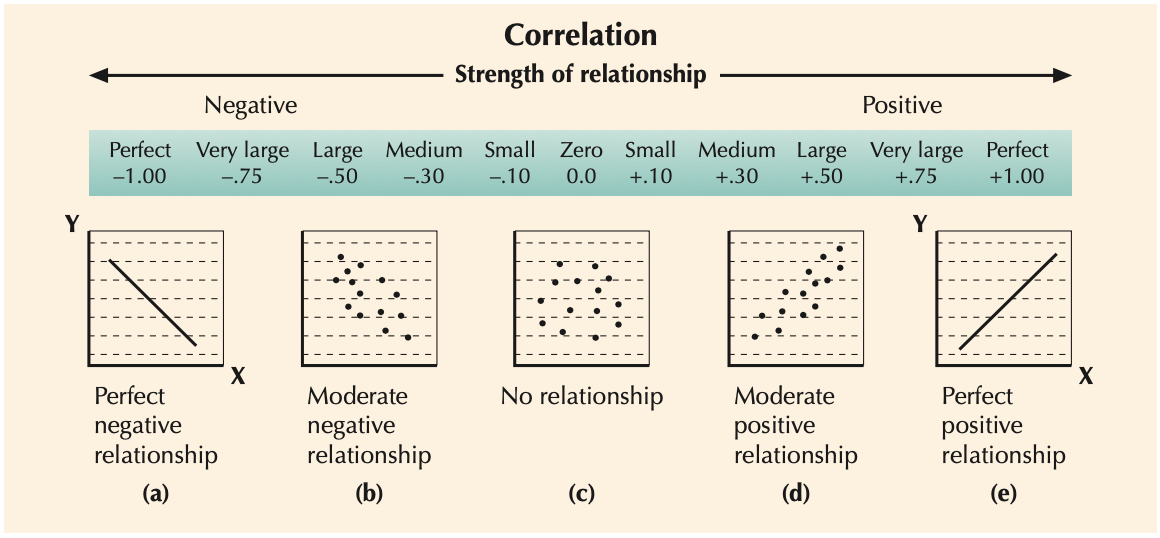

In [31]:
correlation = df.corr(numeric_only=True)

fig = px.imshow(
    correlation,
    template = "plotly_dark",
    text_auto = "0.2f",
    aspect=1,
    color_continuous_scale="orrd",
    title= "Correlations Between Data"
)

fig.update_layout(
    title = {
        "font" :{
            "size" : 28,
            "family" : "tahoma"
        }
    }
)
iplot(fig)

In [32]:
fig = px.scatter_matrix(
    df,
    dimensions=df.select_dtypes(include="number").columns,
    height=800,
    color="Salary",
    opacity=0.65,
    title= "Relationships Between Numerical Data",
    template="plotly_dark"
    
)

fig.update_layout(
    title = {
        "font" :{
            "size" : 28,
            "family" : "tahoma"
        }
    }
)
iplot(fig)

<h3 style = "font: bold 18px arial;
             color: gold;
             background-color: #111;
             padding: 15px;
             border: 2px solid orangere">
    ► From Thses Graphs & Explorations We Can Find Out That:
    <br>
    <br>
    • There is a <b style = "color: tomato">Strong</b> Linear Positive Correlation between Salary and Age
    <br>
    <br>
    • There is a <b style = "color: tomato">Strong</b> Linear Positive Correlation between Salary and Experience Year
</h3>

# I think it's time now to build our model!!🤩👨‍💻

<p style = "color: #F3CCFF;
            font: bold 22px arial;
            padding: 15px;
            background-color: #111;
            border: 3px solid violet;
            border-radius: 8px">
    1] Encoding Categorical Data: (Converting Categorical Into Numerical)
</p>

In [33]:
df_encoded = pd.get_dummies(df, columns=["Education Level"], drop_first=True) *1
df_encoded.head()

,Age,Gender,Job Title,Years of Experience,Salary,Education Level_Master's,Education Level_PhD
0,32.0,Male,Software Engineer,5.0,90000.0,0,0
1,28.0,Female,Data Analyst,3.0,65000.0,1,0
2,45.0,Male,Senior Manager,15.0,150000.0,0,1
3,36.0,Female,Sales Associate,7.0,60000.0,0,0
4,52.0,Male,Director,20.0,200000.0,1,0


<p style = "color: #F3CCFF;
            font: bold 22px arial;
            padding: 15px;
            background-color: #111;
            border: 3px solid violet;
            border-radius: 8px">
    2] Selecting Our Features
</p>

In [34]:
X = df_encoded.drop(columns=["Job Title", "Salary", "Gender"])
y = df_encoded["Salary"]

In [35]:
X.head()

,Age,Years of Experience,Education Level_Master's,Education Level_PhD
0,32.0,5.0,0,0
1,28.0,3.0,1,0
2,45.0,15.0,0,1
3,36.0,7.0,0,0
4,52.0,20.0,1,0


<p style = "color: #F3CCFF;
            font: bold 22px arial;
            padding: 15px;
            background-color: #111;
            border: 3px solid violet;
            border-radius: 8px">
    3] Splitting Our Data
</p>

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=90)

<p style = "color: #F3CCFF;
            font: bold 22px arial;
            padding: 15px;
            background-color: #111;
            border: 3px solid violet;
            border-radius: 8px">
    4] Cross Validation Score
</p>

In [37]:
kf = KFold(n_splits=10, shuffle=True, random_state=30)

In [38]:
rf = RandomForestRegressor(n_estimators=500, random_state=11)

In [39]:
scores = cross_val_score(rf, X, y, cv=kf)
print(f"Cross Validation Score: {np.mean(scores)*100:0.2f}%")

Cross Validation Score: 85.81%


<p style = "color: #F3CCFF;
            font: bold 22px arial;
            padding: 15px;
            background-color: #111;
            border: 3px solid violet;
            border-radius: 8px">
    4] Fitting The Model
</p>

In [40]:
rf.fit(X_train, y_train)

RandomForestRegressor(n_estimators=500, random_state=11)

In [41]:
score = rf.score(X_train, y_train)*100
print(f"Model Score: {np.round(score, 2)}%")

Model Score: 94.15%


<p style = "color: #F3CCFF;
            font: bold 22px arial;
            padding: 15px;
            background-color: #111;
            border: 3px solid violet;
            border-radius: 8px">
    4] Finally, Let's Predict🤗🤩
</p>

In [42]:
predicted_salary = np.round(rf.predict(X_test))

In [43]:
d = {
    "Actual_Salary" : y_test,
    "Predicted_Salary" : predicted_salary,
    "error": predicted_salary - y_test
}
predected_df = pd.DataFrame(d)
predected_df.head()

,Actual_Salary,Predicted_Salary,error
224,160000.0,152630.0,-7370.0
279,140000.0,130743.0,-9257.0
130,160000.0,178505.0,18505.0
186,100000.0,93598.0,-6402.0
149,175000.0,170956.0,-4044.0


In [44]:
score = r2_score(y_test, predicted_salary)*100
print(f"Model Score: {np.round(score, 2)}%")

Model Score: 93.58%


In [45]:
rmse = np.sqrt(mean_squared_error(y_test, predicted_salary))
print(f"Error Ratio: {rmse:.3f}")

Error Ratio: 12844.269


In [46]:
fig = px.scatter(
    predected_df, 
    x = "Actual_Salary", 
    y = "Predicted_Salary",
    color = "error",
    opacity=0.8,
    title= "Predicted Vs. Actual",
    template="plotly_dark",
    trendline="ols"
    
)

fig.update_layout(
    title = {
        "font" :{
            "size" : 28,
            "family" : "tahoma"
        }
    }
)
iplot(fig)

In [47]:
# pd.to_pickle(rf, "random_forest_regressor_salary_predictor_v1.pkl")

# ♦ Streamlit Web APP 🤩🚀

# Web App Linke: <a href = "https://employee-salary-prediction-nerktyf5jc2nvoktlyy6x2.streamlit.app/" style = "color: tomato">Click Here To Visit Streamlit Web App</a>🥰📊

## GitHub Repo: <a href = "https://github.com/modyehab810/Employee-Salary-Prediction">Click Here To Go To GitHub Repo..</a>


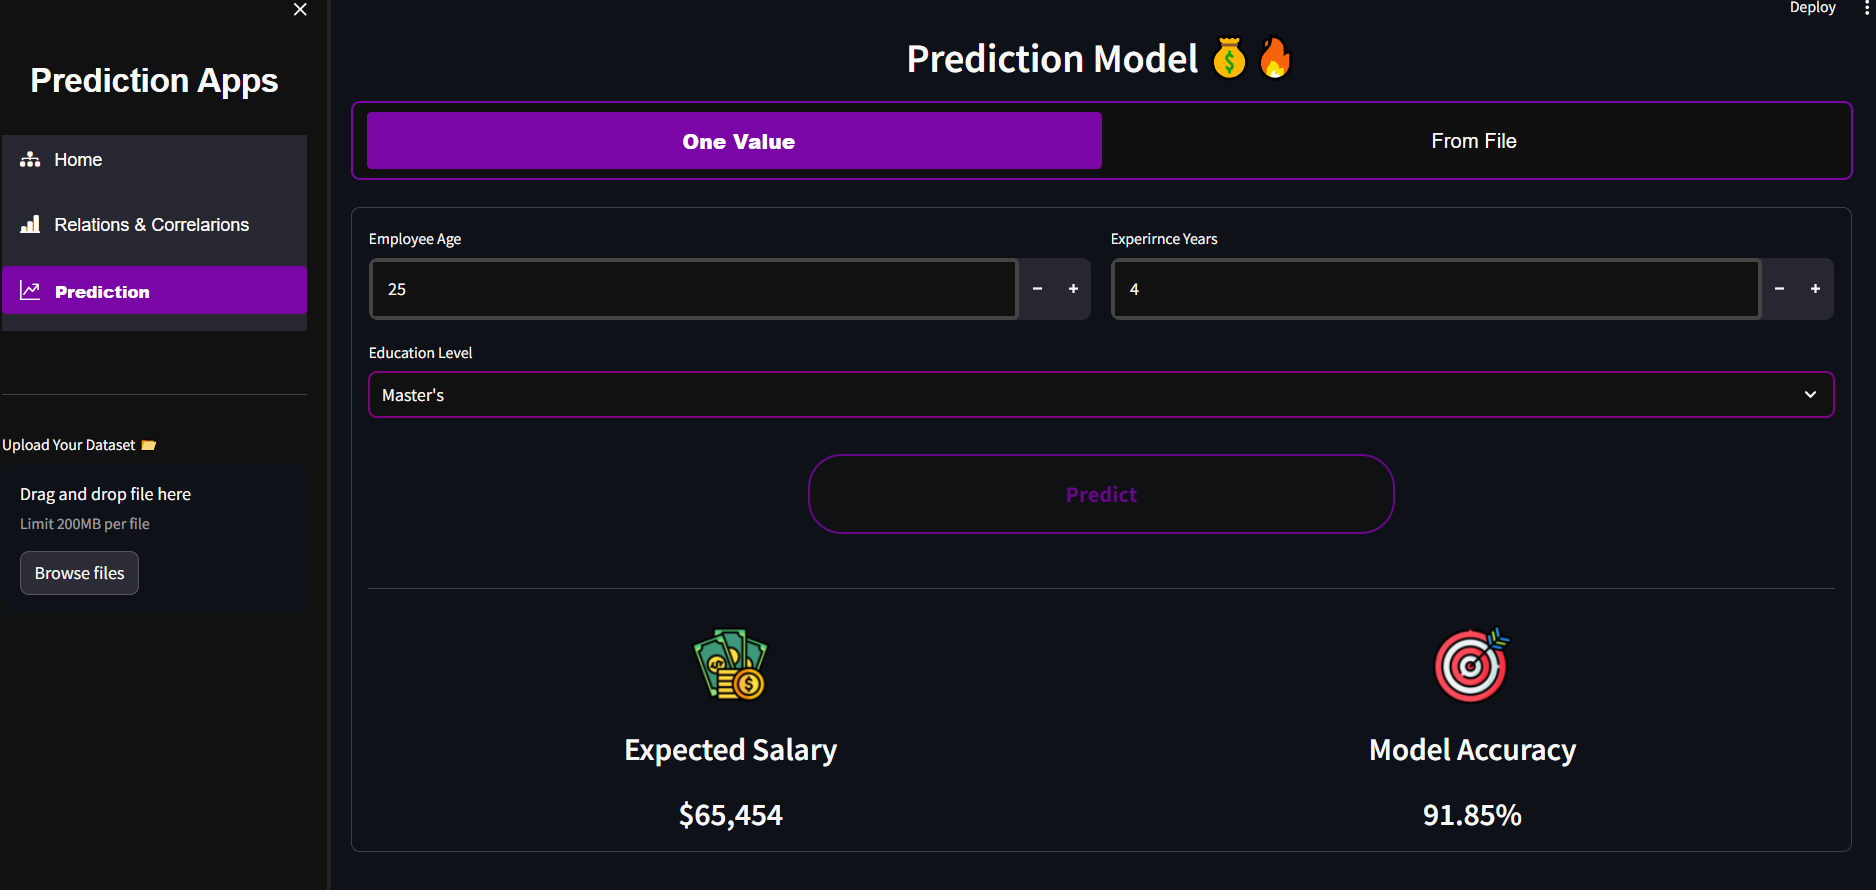